In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qem_bench.backends import get_backend

backend = get_backend()

rows = []
for name in backend.target.operation_names:
    props = backend.target[name]
    errors = [p.error for p in props.values() if p is not None and p.error is not None]
    if errors:
        qargs = next(iter(props))
        rows.append({
            "gate": name,
            "qubits": len(qargs) if qargs else None,
            "median_error": np.median(errors),
            "max_error": np.max(errors),
            "count": len(errors),
        })

gates = pd.DataFrame(rows).sort_values("median_error", ascending=False)
gates

,gate,qubits,median_error,max_error,count
1,measure,1,0.007568,0.105957,156
0,cz,2,0.003903,1.000000,352
2,sx,1,0.000229,0.002488,156
3,id,1,0.000229,0.002488,156
4,x,1,0.000229,0.002488,156
5,rz,1,0.000000,0.000000,156


Text(0.5, 1.0, 'Gate errors on simulated ibm_fez')

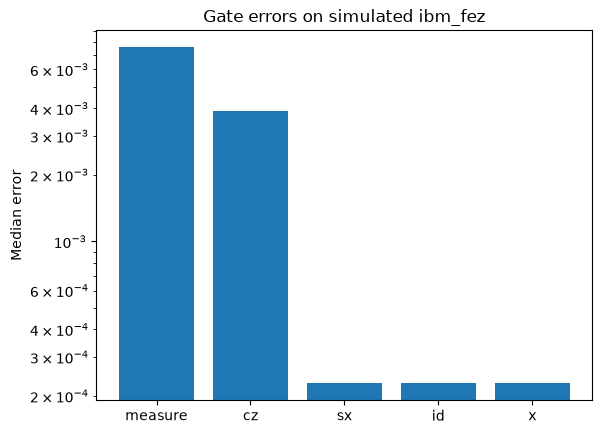

In [2]:
plotted = gates[gates["median_error"] > 0]
plt.bar(plotted["gate"], plotted["median_error"])
plt.yscale("log")
plt.ylabel("Median error")
plt.title("Gate errors on simulated ibm_fez")